In [1]:
# import packages
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# set filepath
#DATA_DIR = Path("Data/")
DATA_DIR = Path("/ourdisk/hpc/ai2es/yxie/")

##### Load the area-weighted monthly mean from 1980-2025

In [3]:
data_regional = np.load(DATA_DIR/"bias_regional_means.npz", allow_pickle=True)

date = data_regional["date"]
regions = data_regional["regions"]
era_tmax_regions = data_regional["era_tmax_regions"]
era_tmin_regions = data_regional["era_tmin_regions"]
obs_tmax_regions = data_regional["obs_tmax_regions"]
obs_tmin_regions = data_regional["obs_tmin_regions"]

In [4]:
# ===== incorporate timestamps ===== # 
# --- pre-allocate arrays
monclim_etmax = np.full((12, len(regions)), np.nan)  # (months, latitude bands)
monclim_otmax = np.full((12, len(regions)), np.nan)
monclim_etmin = np.full((12, len(regions)), np.nan)
monclim_otmin = np.full((12, len(regions)), np.nan)

for i in range(0, len(regions)):    
    # --- for daily TMAX
    s_etmax = pd.Series(np.asarray(era_tmax_regions[:, i].copy(), dtype=float), index=pd.DatetimeIndex(date.copy())).sort_index()
    s_otmax = pd.Series(np.asarray(obs_tmax_regions[:, i].copy(), dtype=float), index=pd.DatetimeIndex(date.copy())).sort_index()
    # --- for daily TMIN
    s_etmin = pd.Series(np.asarray(era_tmin_regions[:, i].copy(), dtype=float), index=pd.DatetimeIndex(date.copy())).sort_index()
    s_otmin = pd.Series(np.asarray(obs_tmin_regions[:, i].copy(), dtype=float), index=pd.DatetimeIndex(date.copy())).sort_index()

    # calculate multi-year monthly mean
    monclim_etmax[:, i] = s_etmax.groupby(s_etmax.index.month).mean().values
    monclim_otmax[:, i] = s_otmax.groupby(s_otmax.index.month).mean().values
    monclim_etmin[:, i] = s_etmin.groupby(s_etmin.index.month).mean().values
    monclim_otmin[:, i] = s_otmin.groupby(s_otmin.index.month).mean().values   

Text(0.0, 1.0, '(b) TMIN mean error')

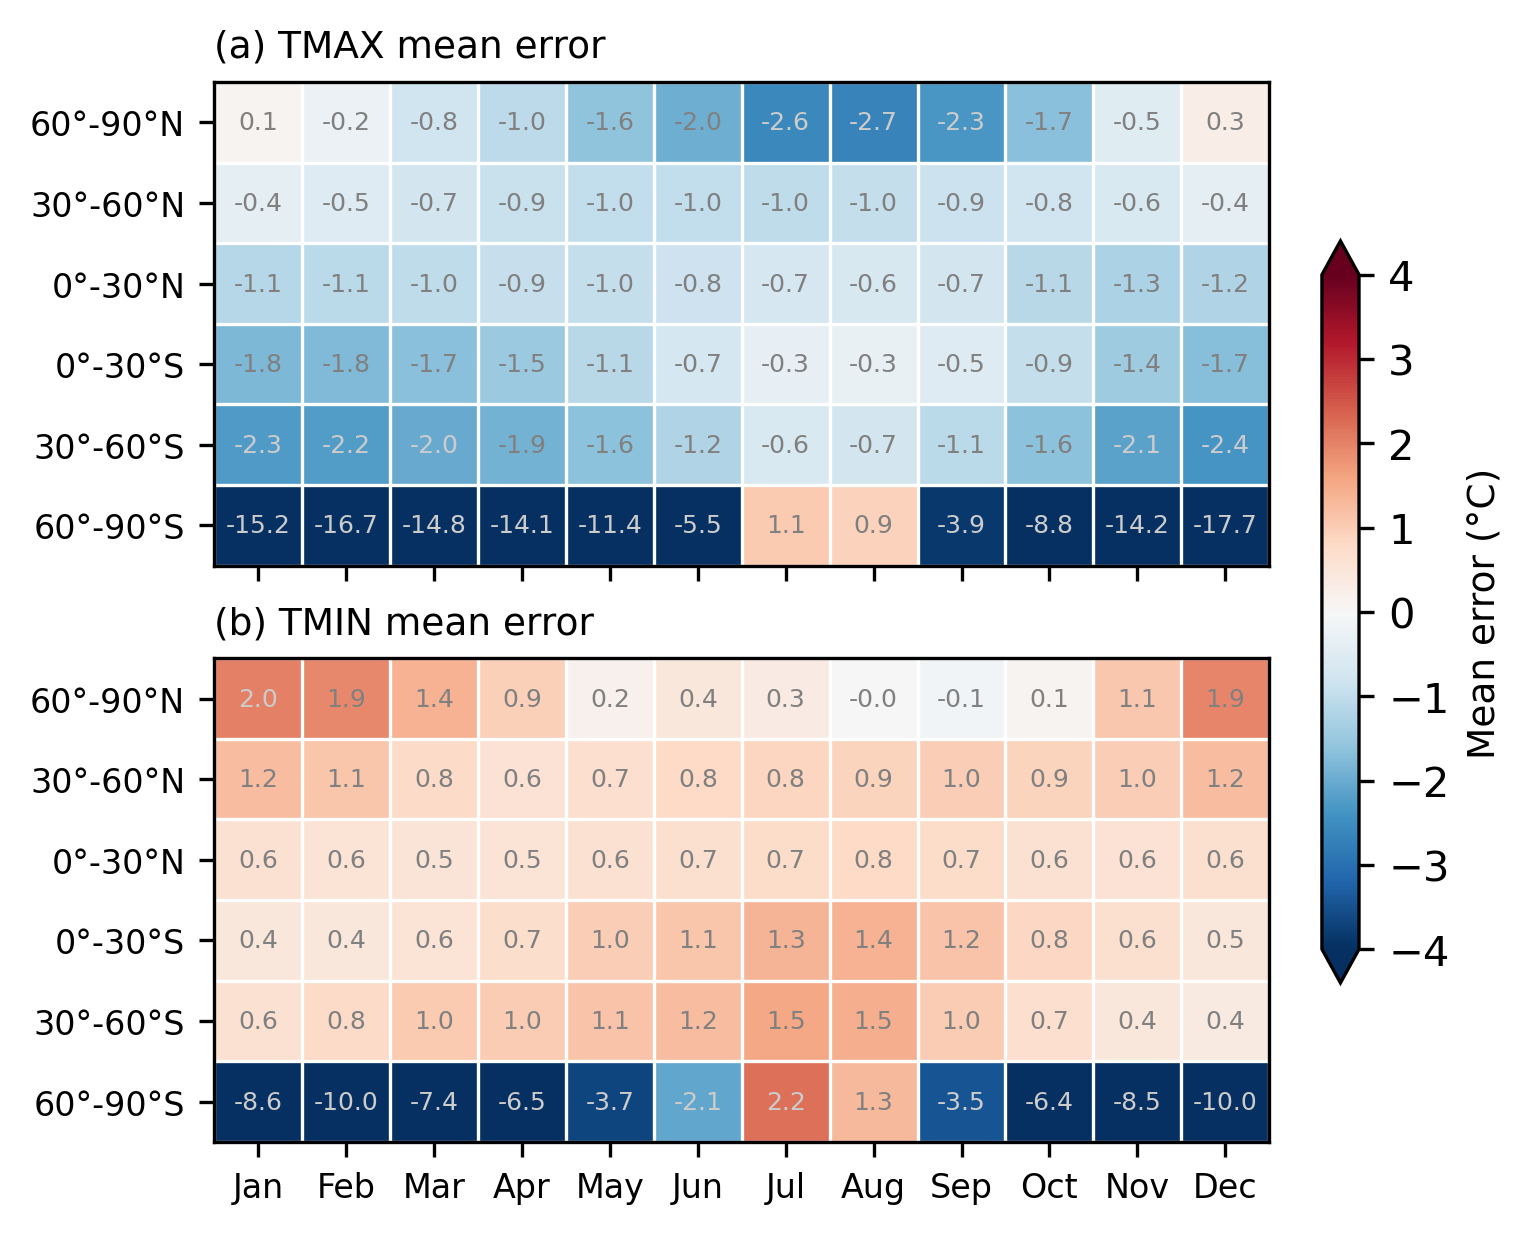

In [5]:
# ===== plot heatmaps ===== #
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(5, 4), sharex=True, constrained_layout=True, dpi=300)
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
latbands = [   
    "60°-90°N",
    "30°-60°N",
    "0°-30°N",
    "0°-30°S",
    "30°-60°S",
    "60°-90°S"
]

vmax = 4

# --- for TMAX --- 
data1 = np.transpose(monclim_etmax - monclim_otmax)
im1 = axes[0].imshow(data1, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
# ticks
#axes[0].set_xticks(np.arange(12))
#axes[0].set_xticklabels(months, fontsize=8)
axes[0].set_yticks(np.arange(6))
axes[0].set_yticklabels(latbands, fontsize=8)

# annotations
for i in range(data1.shape[0]):
    for j in range(data1.shape[1]):
        value = data1[i, j]
        # choose text color automatically
        text_color = "0.8" if abs(value) > vmax * 0.5 else "0.5"
        axes[0].text(j,i,f"{value:.1f}",ha="center",va="center",
            fontsize=6,color=text_color
        )

# colorbar
cbar = fig.colorbar(
    im1,ax=axes,
    pad=0.05,fraction=0.04, shrink=0.7, extend="both"
)
cbar.set_label("Mean error (°C)", fontsize=9)

# minor gridlines
axes[0].set_xticks(np.arange(-0.5, 12, 1), minor=True)
axes[0].set_yticks(np.arange(-0.5, 6, 1), minor=True)
axes[0].grid(which="minor",color="white",linewidth=0.8)
axes[0].tick_params(which="minor", bottom=False, left=False)
axes[0].set_title("(a) TMAX mean error", loc="left", fontsize=9)


# --- for TMIN ---
data2 = np.transpose(monclim_etmin - monclim_otmin)
im2 = axes[1].imshow(data2, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
# ticks
axes[1].set_xticks(np.arange(12))
axes[1].set_xticklabels(months, fontsize=8)
axes[1].set_yticks(np.arange(6))
axes[1].set_yticklabels(latbands, fontsize=8)

# annotations
for i in range(data2.shape[0]):
    for j in range(data2.shape[1]):
        value = data2[i, j]
        # choose text color automatically
        text_color = "0.8" if abs(value) > vmax * 0.5 else "0.5"
        axes[1].text(j,i,f"{value:.1f}",ha="center",va="center",
            fontsize=6,color=text_color
        )

# minor gridlines
axes[1].set_xticks(np.arange(-0.5, 12, 1), minor=True)
axes[1].set_yticks(np.arange(-0.5, 6, 1), minor=True)
axes[1].grid(which="minor",color="white",linewidth=0.8)
axes[1].tick_params(which="minor", bottom=False, left=False)
axes[1].set_title("(b) TMIN mean error", loc="left", fontsize=9)
